In [70]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from llm.model import llm_model
from langgraph.checkpoint.memory import InMemorySaver

In [71]:
model = llm_model()

In [72]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [73]:
def generate_joke(state: JokeState):

    # fetch topic
    # topic = state['topic']

    prompt = f'Genrate a unique and funny joke on the topic - {state["topic"]}'

    response = model.invoke(prompt).content

    return {'joke': response}

In [74]:
def explain_joke(state: JokeState):

    # fetch Joke and topic
    topic = state['topic']
    joke = state['joke']

    prompt = f"write the explanation for the joke - {state['joke']}"

    response = model.invoke(prompt).content

    return {'explanation': response}

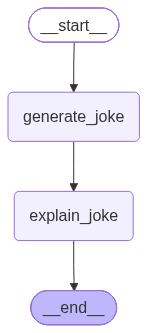

In [75]:
checkpointer = InMemorySaver()

graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('explain_joke', explain_joke)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'explain_joke')
graph.add_edge('explain_joke', END)

workflow = graph.compile(checkpointer=checkpointer)

workflow

In [76]:
thread_id = '1'

initial_state = {
    'topic': 'Nepali'

}
config = {'configurable': {'thread_id': thread_id}}
final_state = workflow.invoke(initial_state, config)

print(final_state)

{'topic': 'Nepali', 'joke': 'Why did the Nepali go to the doctor? To get their "sah" checked!', 'explanation': 'The joke is a play on words, using the word "sah" which is a Nepali word meaning "sick" or "unwell." The punchline is that the Nepali went to the doctor to get their "sah" checked, which is a play on the word "check." The joke is a light-hearted way of saying that someone went to the doctor because they were sick, but the punchline is a play on words that makes the joke a bit silly and unexpected.'}


In [77]:
# Second Joke Generate
config2 = {'configurable': {'thread_id': 2}}

workflow.invoke({'topic': 'MoMo'}, config=config2)

{'topic': 'MoMo',
 'joke': 'Why did MoMo break up with his girlfriend? Because he realized she was just a "doughnut" in his life.',
 'explanation': 'The joke is a play on words and a common stereotype about people\'s relationship with food. "MoMo" is likely a nickname for a man named Mo, and "doughnut" is a type of food. The joke is suggesting that Mo realized his girlfriend was not as important or significant in his life as food, specifically a doughnut. It\'s a humorous way of implying that someone\'s partner is not as important or meaningful as something they consume, like a doughnut.'}

In [78]:
workflow.get_state(config=config2)

StateSnapshot(values={'topic': 'MoMo', 'joke': 'Why did MoMo break up with his girlfriend? Because he realized she was just a "doughnut" in his life.', 'explanation': 'The joke is a play on words and a common stereotype about people\'s relationship with food. "MoMo" is likely a nickname for a man named Mo, and "doughnut" is a type of food. The joke is suggesting that Mo realized his girlfriend was not as important or significant in his life as food, specifically a doughnut. It\'s a humorous way of implying that someone\'s partner is not as important or meaningful as something they consume, like a doughnut.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e9bdf-a6bc-67a7-8002-6a4c8cf923c6'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-26T17:22:38.465332+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e9bdf-8de0-6ac2-8001-987b874a9b5c'}}, tasks=(), interrupt

In [79]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'MoMo', 'joke': 'Why did MoMo break up with his girlfriend? Because he realized she was just a "doughnut" in his life.', 'explanation': 'The joke is a play on words and a common stereotype about people\'s relationship with food. "MoMo" is likely a nickname for a man named Mo, and "doughnut" is a type of food. The joke is suggesting that Mo realized his girlfriend was not as important or significant in his life as food, specifically a doughnut. It\'s a humorous way of implying that someone\'s partner is not as important or meaningful as something they consume, like a doughnut.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e9bdf-a6bc-67a7-8002-6a4c8cf923c6'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-26T17:22:38.465332+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e9bdf-8de0-6ac2-8001-987b874a9b5c'}}, tasks=(), interrup

# Time Traval

In [83]:
workflow.get_state({'configurable': {'thread_id': '2', 'checkpoint_id': '1f1e9a1b-f717-6ca2-8000-a682b017df5b'}})

StateSnapshot(values={}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f1e9a1b-f717-6ca2-8000-a682b017df5b'}}, metadata=None, created_at=None, parent_config=None, tasks=(), interrupts=())

In [85]:
workflow.invoke(None, {'configurable': {'thread_id': '2', 'checkpoint_id': '1f1e9bdf-8593-6710-8000-3ddf9d1f7035'}})

{'topic': 'MoMo',
 'joke': 'Why did MoMo break up with his girlfriend? Because he realized she was just a "Momo" in the app.',
 'explanation': 'The joke is a play on words, using the word "Momo" as both a name and a term. The girlfriend is referred to as a "Momo" in the app, which is likely a reference to a social media app or platform. The girlfriend is not actually a "Momo" in the app, but rather a person who is using the app to communicate with her boyfriend. The boyfriend realizes that she is not actually a "Momo" in the app, but rather a real person who is using the app to communicate with him. This is why he breaks up with her. The joke is a play on the idea that sometimes people can be deceived by the technology they use, and that they may not actually be communicating with the people they think they are.'}

In [86]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'MoMo', 'joke': 'Why did MoMo break up with his girlfriend? Because he realized she was just a "Momo" in the app.', 'explanation': 'The joke is a play on words, using the word "Momo" as both a name and a term. The girlfriend is referred to as a "Momo" in the app, which is likely a reference to a social media app or platform. The girlfriend is not actually a "Momo" in the app, but rather a person who is using the app to communicate with her boyfriend. The boyfriend realizes that she is not actually a "Momo" in the app, but rather a real person who is using the app to communicate with him. This is why he breaks up with her. The joke is a play on the idea that sometimes people can be deceived by the technology they use, and that they may not actually be communicating with the people they think they are.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e9be5-6efa-6056-8003-4c8478f63dc3'}}, metadata={'source': '

# Updating State 

In [90]:
workflow.update_state({'configurable': {'thread_id': '2', 'checkpoint_id': '1f1e9bdf-8593-6710-8000-3ddf9d1f7035', 'checkpoint_ns': ''}}, {'topic': 'samosa'})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e9bea-7bfb-6d9c-8001-d7bd252a02ab'}}

In [92]:
workflow.invoke(None, {'configurable': {'thread_id': '2', 'checkpoint_id':'1f1e9be6-c6a0-670e-8001-e2e8b7b57df6'}})

{'topic': 'samosa',
 'joke': 'Why did the samosa break up with its girlfriend? Because the samosa was too spicy for her!',
 'explanation': 'The joke is a play on words and a pun. The punchline "Because the samosa was too spicy for her" is a play on the word "spicy" and the word "spice" (as in the samosa\'s filling). The joke is that the samosa is a food item, and it can\'t actually break up with a girlfriend. The punchline is a play on words, where the word "spicy" is used twice, once as a descriptor of the samosa\'s filling and once as a descriptor of the samosa itself. The joke is that the samosa is too spicy for its girlfriend, which is a play on the idea that spicy food can be too strong or intense for some people.'}

In [93]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa break up with its girlfriend? Because the samosa was too spicy for her!', 'explanation': 'The joke is a play on words and a pun. The punchline "Because the samosa was too spicy for her" is a play on the word "spicy" and the word "spice" (as in the samosa\'s filling). The joke is that the samosa is a food item, and it can\'t actually break up with a girlfriend. The punchline is a play on words, where the word "spicy" is used twice, once as a descriptor of the samosa\'s filling and once as a descriptor of the samosa itself. The joke is that the samosa is too spicy for its girlfriend, which is a play on the idea that spicy food can be too strong or intense for some people.'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1e9bef-ba94-6bc2-8004-2f41d393bd4a'}}, metadata={'source': 'loop', 'step': 4, 'parents': {}}, created_at='2026-11-26T17:29:50.043009+00:00', parent_config=